## **Crop Yield Prediction Using  Linear Regression**

  Goal: To predict crop yield using Simple and Multiple Linear Regression based on rainfall, soil quality, farm size, sunlight hours, and fertilizer usage.

In [1]:
## Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split

In [9]:

df = pd.read_csv('crop_yield_data.csv')

In [10]:
## Display first five rows
df.head()

,rainfall_mm,soil_quality_index,farm_size_hectares,sunlight_hours,fertilizer_kg,crop_yield
0,1061.810178,6.778285,2.443734,5.351481,736.514771,455.198271
1,1926.071460,1.757260,13.635741,6.228723,237.285139,552.414188
2,1597.990913,2.454658,8.073533,5.416084,618.659524,516.614495
3,1397.987726,9.086988,12.570405,4.709620,646.043542,596.560798
4,734.027961,6.457862,5.480694,4.965087,481.717604,374.497522


In [11]:
## Statistical description of dataset
df.describe()

,rainfall_mm,soil_quality_index,farm_size_hectares,sunlight_hours,fertilizer_kg,crop_yield
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,1226.009350,5.539376,8.289419,7.830169,517.111718,501.121184
std,442.337147,2.637011,4.302323,2.230677,256.799520,100.863565
min,508.283176,1.045554,1.151727,4.144881,104.168821,312.276000
25%,842.873622,3.353163,4.577284,5.887786,288.460683,425.844687
50%,1241.729380,5.874759,8.355593,7.737024,499.045834,498.794646
75%,1635.289424,7.679794,12.355608,9.795250,720.978324,579.772756
max,1980.330405,9.914546,14.996047,11.919682,997.186827,762.413682


In [12]:
## Check missing values
df.isnull().sum()

,0
rainfall_mm,0
soil_quality_index,0
farm_size_hectares,0
sunlight_hours,0
fertilizer_kg,0
crop_yield,0


In [13]:
## Clean the data
# All columns in this dataset are numeric.
# Fill missing numeric values with the median of each column.
df = df.fillna(df.median(numeric_only=True))

# Remove duplicate rows, if any
df = df.drop_duplicates()

df.isnull().sum()

,0
rainfall_mm,0
soil_quality_index,0
farm_size_hectares,0
sunlight_hours,0
fertilizer_kg,0
crop_yield,0


In [15]:
## View cleaned dataset
df.head()

,rainfall_mm,soil_quality_index,farm_size_hectares,sunlight_hours,fertilizer_kg,crop_yield
0,1061.810178,6.778285,2.443734,5.351481,736.514771,455.198271
1,1926.071460,1.757260,13.635741,6.228723,237.285139,552.414188
2,1597.990913,2.454658,8.073533,5.416084,618.659524,516.614495
3,1397.987726,9.086988,12.570405,4.709620,646.043542,596.560798
4,734.027961,6.457862,5.480694,4.965087,481.717604,374.497522


In [18]:
## Features (independent variables) and target (dependent variable)
# We use all columns except crop_yield to predict crop_yield.
X = df.drop('crop_yield', axis=1)
y = df['crop_yield']

In [19]:
## Display input features
X.head()

,rainfall_mm,soil_quality_index,farm_size_hectares,sunlight_hours,fertilizer_kg
0,1061.810178,6.778285,2.443734,5.351481,736.514771
1,1926.071460,1.757260,13.635741,6.228723,237.285139
2,1597.990913,2.454658,8.073533,5.416084,618.659524
3,1397.987726,9.086988,12.570405,4.709620,646.043542
4,734.027961,6.457862,5.480694,4.965087,481.717604


In [20]:
## Display target
y.head()

,crop_yield
0,455.198271
1,552.414188
2,516.614495
3,596.560798
4,374.497522


In [21]:
## Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

**Simple linear regression (1 feature)**

In [22]:
## Finding the feature most correlated with crop yield and perform simple linear regression
best = df.corr(numeric_only=True)['crop_yield'].drop('crop_yield').abs().idxmax()
print("Best feature:", best)

simple = LinearRegression()
simple.fit(X_train[[best]], y_train)

print("Intercept:", simple.intercept_)
print("Slope:", simple.coef_[0])
print("R2:", r2_score(y_test, simple.predict(X_test[[best]])))

Best feature: rainfall_mm
Intercept: 267.7291493550512
Slope: 0.190536582306092
R2: 0.7295086223786195


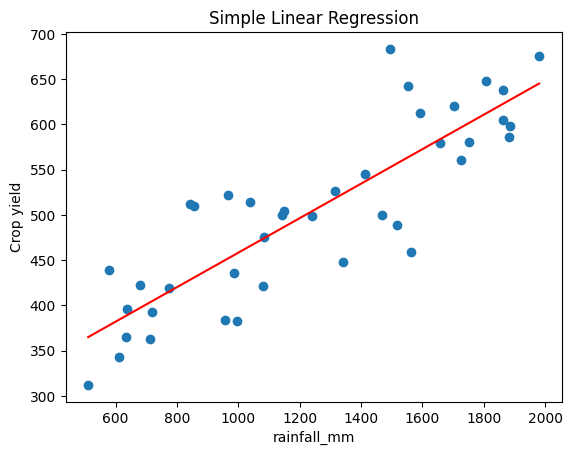

In [23]:
## Plot simple linear regression
# Sort x-values so the regression line appears in the correct order.
plot_data = pd.DataFrame({
    best: X_test[best].values,
    'actual_yield': y_test.values,
    'predicted_yield': simple.predict(X_test[[best]])
}).sort_values(by=best)

plt.scatter(X_test[best], y_test)
plt.plot(plot_data[best], plot_data['predicted_yield'], color='red')
plt.xlabel(best)
plt.ylabel('Crop yield')
plt.title('Simple Linear Regression')
plt.show()

**Multiple linear regression (all features)**

In [24]:
## Train multiple linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [25]:
## Making predictions on test data
y_pred = model.predict(X_test)

In [26]:
## Evaluate the model
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("MAE:", mae)
print("R2:", r2)

MSE: 78.4076637063342
MAE: 6.790028849807507
R2: 0.9917284100679364


In [27]:
## Display intercept and coefficients
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: 4.976395507549512
Coefficients: [ 0.19698775 14.98565813  5.27121722  9.85078509  0.09794337]


In [28]:
## Display feature-wise coefficients
coef_df = pd.DataFrame(model.coef_, index=X.columns, columns=['Coefficient'])
coef_df

,Coefficient
rainfall_mm,0.196988
soil_quality_index,14.985658
farm_size_hectares,5.271217
sunlight_hours,9.850785
fertilizer_kg,0.097943


**Residuals (actual - predicted):**

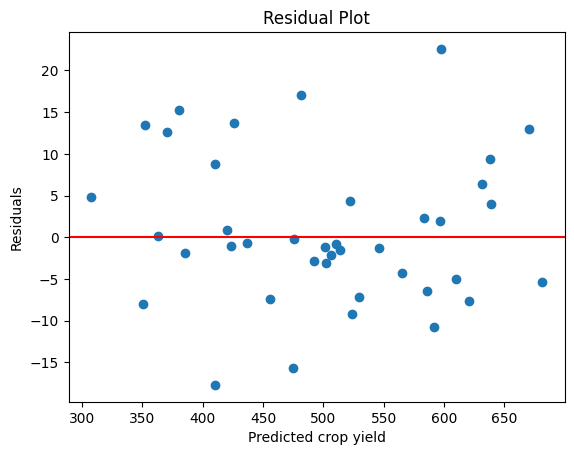

In [29]:
## Residual plot
residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(0, color='red')
plt.xlabel('Predicted crop yield')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

**Least squares by hand (normal equation)**


In [30]:
## Calculate coefficients using the normal equation
# pinv is used instead of inverse so the calculation is more robust.
A = np.c_[np.ones(len(X_train)), X_train.values]  # Add a column of 1s for intercept
beta = np.linalg.pinv(A) @ y_train.values

print("Intercept:", beta[0])
print("Coefficients:", beta[1:])

Intercept: 4.976395507548375
Coefficients: [ 0.19698775 14.98565813  5.27121722  9.85078509  0.09794337]


**Test the model with new data**

In [31]:
## Predict crop yield for new input values
new_data = pd.DataFrame({
    'rainfall_mm': [1500],
    'soil_quality_index': [7],
    'farm_size_hectares': [5],
    'sunlight_hours': [8],
    'fertilizer_kg': [500]
})

predicted_yield = model.predict(new_data[X.columns])
print("Predicted crop yield:", predicted_yield[0])

Predicted crop yield: 559.4916742105852


In [32]:
## Take input from user and predict crop yield
rainfall = float(input("Rainfall (mm): "))
soil_quality = float(input("Soil quality index: "))
farm_size = float(input("Farm size (hectares): "))
sunlight = float(input("Sunlight hours: "))
fertilizer = float(input("Fertilizer (kg): "))

user_data = pd.DataFrame({
    'rainfall_mm': [rainfall],
    'soil_quality_index': [soil_quality],
    'farm_size_hectares': [farm_size],
    'sunlight_hours': [sunlight],
    'fertilizer_kg': [fertilizer]
})

prediction = model.predict(user_data[X.columns])[0]
print(f"\\nPredicted crop yield: {prediction:.2f}")

Rainfall (mm): 222
Soil quality index: 234.5
Farm size (hectares): 5.55
Sunlight hours: 4
Fertilizer (kg): 50
\nPredicted crop yield: 3636.40
